In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import numpy as np
import scipy as sp

In [3]:
import matplotlib.pyplot as plt
%matplotlib inline
plt.rcParams["figure.figsize"] = [12,8]
from matplotlib.patches import Arc, FancyArrowPatch

In [4]:
import lighthouse as lh

# Lighthouse

This problem is taken from "Data Analysis, a Bayesian Tutorial" by D.S. Silva with J. Skiling. A lighthouse distance $h=1$ from the shore is rotating with constant angular frequency and emitting thin beams of light at random. The probability of emission is uniform in time. The signals are picked up on the shore by an array of detectors and their location is saved in the file `lighthouse.txt`.  The horizontal location of the lighthouse $x_{lh}$ is unknown. The task is to estimate this position.

In [5]:
h=1

In [6]:
flash_x = np.loadtxt('lighthouse.txt')

The figure below  presents the geometry of the problem. The orange dot indicates the lighthouse. Blue dots are the points were the flashes were recorded. The directions of the first 10 flashes are shown as lightblue lines.

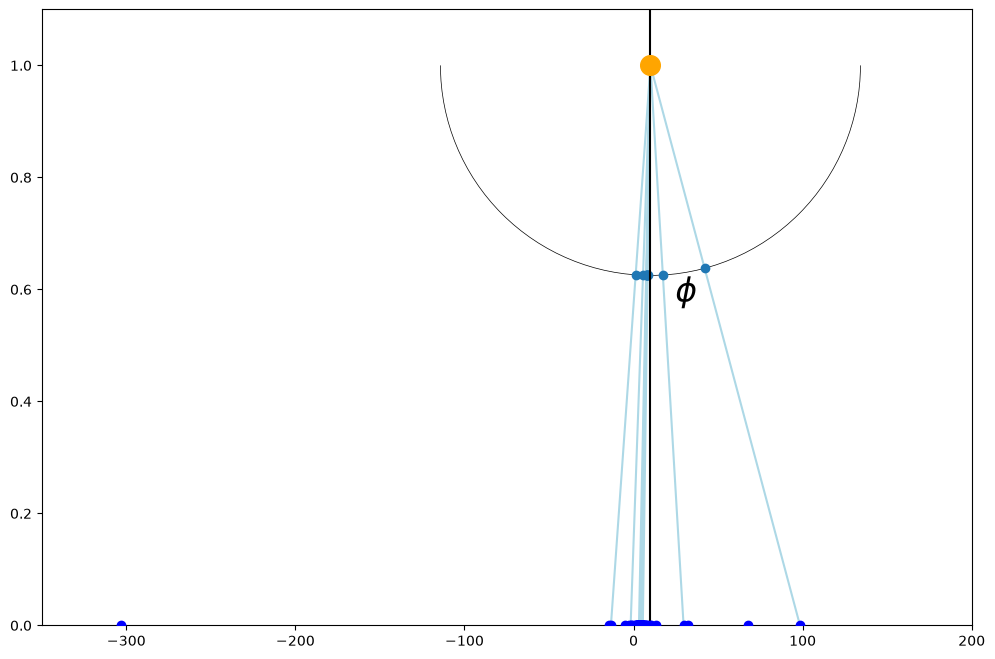

In [7]:
x0=10;
fig,ax=plt.subplots();
ax.set_ylim(0,1.1)
ax.set_xlim(-350,200)
aspect = lh.get_aspect(ax)

ax.scatter(flash_x,np.zeros_like(flash_x), zorder=10, c='blue');
ax.axvline(x0, color='black')

for i in range(10):
    ax.plot([flash_x[i],x0],[0,1], c='lightblue', zorder=-10)    
ax.scatter([x0],[1],s=200, zorder=10, c='orange');
thetas=np.arctan((flash_x[:10]-x0)*aspect)
arc3=Arc((x0,h),width=0.75/aspect,height=0.75, angle=0, theta1=np.rad2deg(-np.pi), theta2=0,
         edgecolor='black', linewidth=0.5);
ax.add_patch(arc3);
ax.scatter(*lh.polar2xy((x0,h),-np.pi/2+thetas,0.75/(2*aspect), aspect=aspect));
xy = lh.polar2xy((x0,h),-np.pi/2+np.pi/30,0.85/(2*aspect), aspect=aspect)
ax.annotate(r"$\phi$",xy, fontsize=24);

## Sampling distribution

Under those conditions the sampling distribution is the Cauchy distribution with probability density function

$$p(x|x_{lh},h)=\frac{h}{\pi}\frac{1}{\left(x-x_{lh}\right)^2+h^2}$$

In the following we will drop the subscript $X$ on $p$.

## Problem 1

Assuming an uniform prior on interval $[-x_{lim}, x_{lim})$ with $x_{lim}=100$ for $x_{lh}$  plot the posterior distribution after performing one measurement.  Represent posterior density function by an array $p_{post}(xs_i)$ where $xs_i$ are uniformly distributed on the interval  $[-x_{lim}, x_{lim})$:

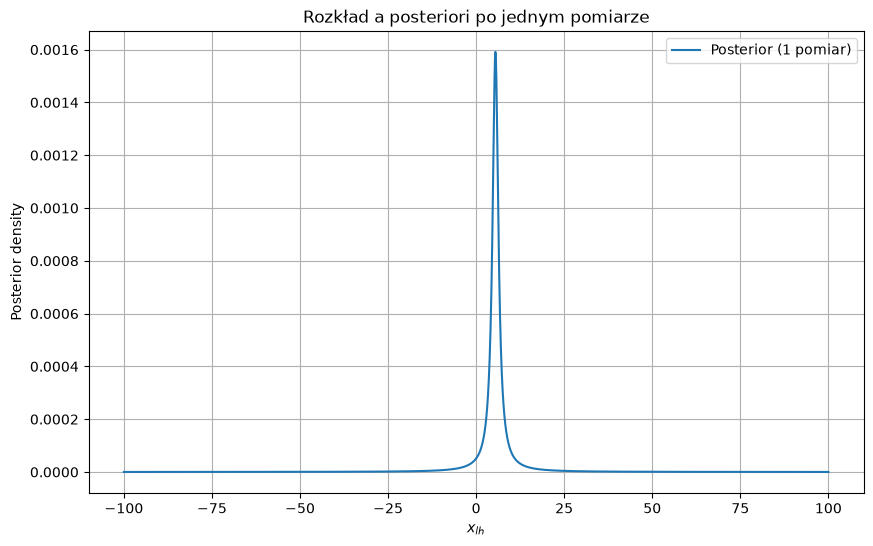

In [8]:
x_lim=100.0
xs=np.linspace(-x_lim, x_lim,5000)
prior = np.ones_like(xs) / (2 * x_lim)
x_obs = flash_x[0] #Pierwszy czujnik
def cauchy_likelihood(obs, xlh, h=1.0):
    return (h / np.pi) / ((obs - xlh)**2 + h**2)

like_1 = cauchy_likelihood(x_obs, xs, h)
posterior_unnorm = like_1 * prior
plt.figure(figsize=(10, 6))
plt.plot(xs, posterior_unnorm, label="Posterior (1 pomiar)")
plt.xlabel("$x_{lh}$")
plt.ylabel("Posterior density")
plt.title("Rozkład a posteriori po jednym pomiarze")
plt.legend()
plt.grid(True)
plt.show()

Normalize the $p(xs_i)$ such that

$$\sum_i p(xs_i)=1$$

Find and printout the maximal a posteriori (MAP) estimate for $x_{lh}$.

In [9]:
# Normalizacja

Z = np.sum(posterior_unnorm)
posterior = posterior_unnorm / Z

map_idx = np.argmax(posterior)
map_estimate = xs[map_idx]
print(f"Pierwszy pomiar x_obs = {x_obs}")
print(f"MAP (po 1 pomiarze) = {map_estimate}")

Pierwszy pomiar x_obs = 5.486526822131198
MAP (po 1 pomiarze) = 5.501100220044009


## Problem 2

Add the plot of the posterior after two measurments. 

**Hint** perform same calculations as in problem 1, but use the calculated posterior as the new prior. Calculate the MAP estimate.

MAP po 2. pomiarach = 5.3411


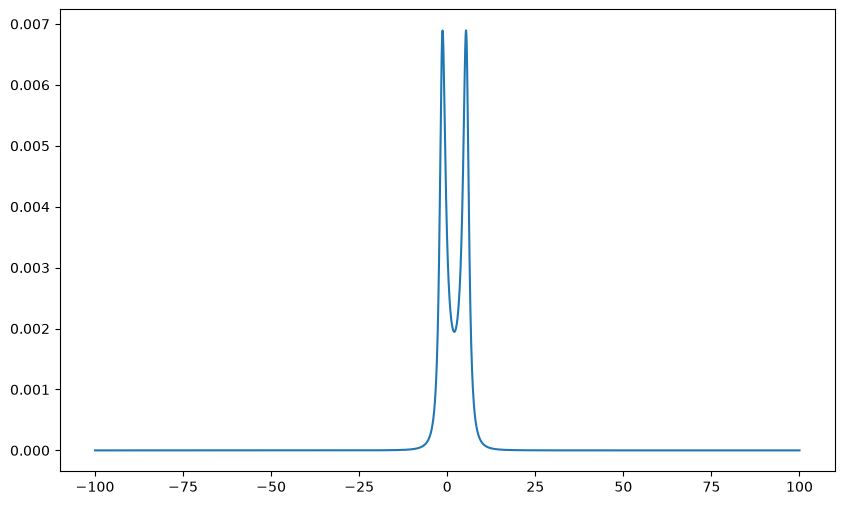

In [10]:
x_obs2 = flash_x[95] #Uziąłem 95 czujnik bo tam na minusie jest położenie i chciałem sprawdzić
x_obs2 = flash_x[94] #Uziąłem 95 czujnik bo tam na minusie jest położenie i chciałem sprawdzić
prior_2 = posterior
like_2 = cauchy_likelihood(x_obs2, xs, h)
posterior_2_unnorm = prior_2 * like_2
posterior_2 = posterior_2_unnorm / np.sum(posterior_2_unnorm)

# MAP (po 2. pomiarach)
map_idx_2 = np.argmax(posterior_2)
map_estimate_2 = xs[map_idx_2]
print(f"MAP po 2. pomiarach = {map_estimate_2:.4f}")
plt.figure(figsize=(10, 6))
plt.plot(xs, posterior_2, label="Posterior po 2. pomiarach")

## Problem 3

Write an iterative procedure that calculates all the posteriors ans all MAP estimates corresponding to $1,\ldots,100$ measurements. Plot first 10 and last 10 posterior distributions. What is the final MAP? Find 95% probability symmetric interval around this value.

Final MAP after 100 measurements = 4.0208
Symmetric 95% interval around MAP: [3.8608, 5.2210]


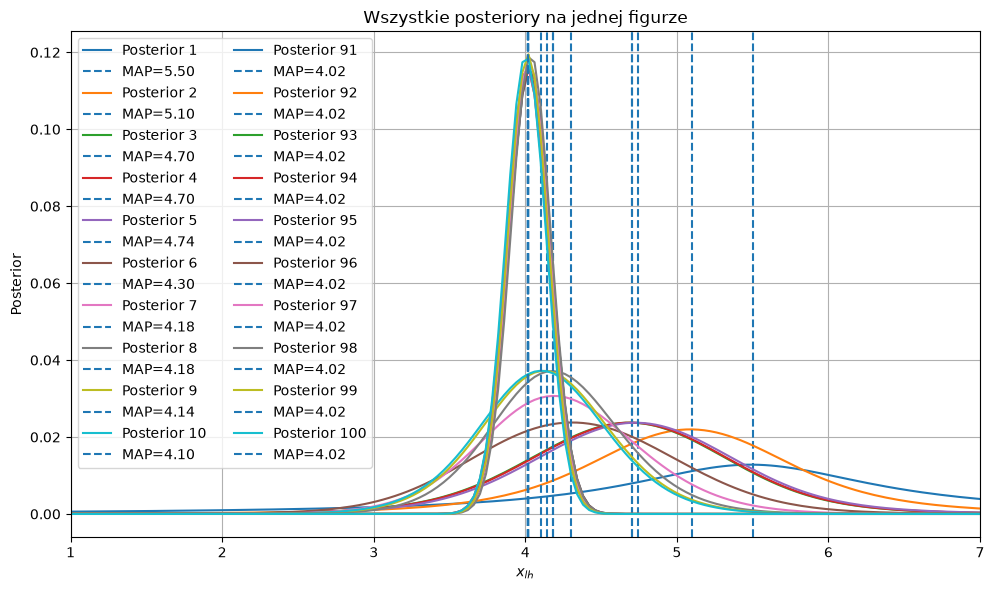

Symmetric 95% interval around MAP: [3.8608, 5.2210]


In [11]:
N = 100
measurements = flash_x[:N]
all_posteriors = []
all_MAPs = []
current_prior = prior


# Iterujemy po pomiarach i aktualizujemy posterior

for i, x_obs in enumerate(measurements, start=1):
    like = cauchy_likelihood(x_obs, xs, h)
    posterior_unnorm = current_prior * like
    Z = np.sum(posterior_unnorm)
    posterior = posterior_unnorm / Z
    map_idx = np.argmax(posterior)
    map_estimate = xs[map_idx]
    
    all_posteriors.append(posterior)
    all_MAPs.append(map_estimate)
    current_prior = posterior

final_MAP = all_MAPs[-1]
print(f"Final MAP after {N} measurements = {final_MAP:.4f}")
final_posterior = all_posteriors[-1]

cdf = np.cumsum(final_posterior)
cdf /= cdf[-1]  

map_index = np.argmax(final_posterior)
cdf_map = cdf[map_index]

delta = 0.475

left_cdf_val = cdf_map - delta
right_cdf_val = cdf_map + delta

left_cdf_val = max(left_cdf_val, 0.0)
right_cdf_val = min(right_cdf_val, 1.0)

left_idx = np.searchsorted(cdf, left_cdf_val)
right_idx = np.searchsorted(cdf, right_cdf_val)

left_bound = xs[left_idx]
right_bound = xs[right_idx]

print(f"Symmetric 95% interval around MAP: [{left_bound:.4f}, {right_bound:.4f}]")

# Rysujemy wszystko na jednym wykresie
plt.figure(figsize=(10, 6))

# Najpierw 10 pierwszych posteriorów
for i in range(10):
    plt.plot(xs, all_posteriors[i], label=f"Posterior {i+1}")
    plt.axvline(all_MAPs[i], linestyle='--', label=f"MAP={all_MAPs[i]:.2f}")

# Następnie 10 ostatnich posteriorów
for i in range(10):
    idx = N - 10 + i
    plt.plot(xs, all_posteriors[idx], label=f"Posterior {idx+1}")
    plt.axvline(all_MAPs[idx], linestyle='--', label=f"MAP={all_MAPs[idx]:.2f}")

plt.title("Wszystkie posteriory na jednej figurze")
plt.xlabel("$x_{lh}$")
plt.ylabel("Posterior")
plt.legend(ncol=2)  # Można ustawić liczbę kolumn legendy, żeby się lepiej rozłożyła
plt.grid(True)
plt.tight_layout()
plt.xlim(1, 7)
plt.show()

print(f"Symmetric 95% interval around MAP: [{left_bound:.4f}, {right_bound:.4f}]")

## Problem 4

Write a procedure that takes as the input $xs$ array, the prior array,  array of measurments and returns the posterior "in one go". 

**Hint** it is easier to work with logarithms of probabilities. For normalizing you can use `logsumexp` function from `scipy.special`. If you need to use a loop in your code, please loop over the measurments.

Suma posteriora = 1.0000000000000266
MAP = 4.020804160832171


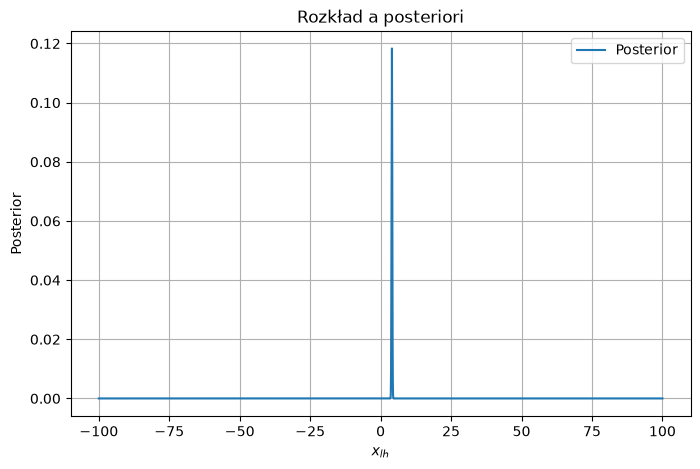

In [12]:
from scipy.special import logsumexp
def cauchy_log_likelihood(meas, xlh, h=1.0):
    return np.log(h / np.pi) - np.log((meas - xlh) ** 2 + h ** 2)

def posterior_in_one_go(xs, prior, measurements, h=1.0):
    log_prior = np.log(prior)
    log_posterior = log_prior.copy()
    for meas in measurements:
        log_like = cauchy_log_likelihood(meas, xs, h)
        log_posterior += log_like
    log_norm = logsumexp(log_posterior)
    log_posterior -= log_norm
    posterior = np.exp(log_posterior)
    return posterior
posterior4 = posterior_in_one_go(xs, prior, measurements, h=1.0)

print("Suma posteriora =", np.sum(posterior4))

map_idx = np.argmax(posterior4)
map_estimate4 = xs[map_idx]
print("MAP =", map_estimate4)
plt.figure(figsize=(8,5))
plt.plot(xs, posterior4, label="Posterior")
plt.xlabel("$x_{lh}$")
plt.ylabel("Posterior")
plt.title("Rozkład a posteriori")
plt.legend()
plt.grid(True)
plt.show()